# Example: load a log image, plot its bounding boxes, visualise the results

This notebook walks through the three pieces in the `example` folder:

| File | What it is |
|---|---|
| `0000000009_d-582_0000020435-0001_log06_fe_5in_md.tif` | the log image (a large 1-bit scan) |
| `0000000009_d-582_0000020435-0001_log06_fe_5in_md.json` | the annotation: bounding boxes for the columns and the lithology legend |
| `example.csv` | an example **output**: one row per lithology interval, with its depth range and its position (pixel rows) in the image |

It only needs `numpy` and `Pillow`, so it runs in any standard Python environment.
Run it from the `project/` folder so the relative `example` path resolves.

## 1. Setup

In [1]:
import os
import colorsys
import csv
import json
from pathlib import Path

import numpy as np
from PIL import Image, ImageDraw, ImageFont

Image.MAX_IMAGE_PIXELS = None  # these scans are very large; disable Pillow's decompression-bomb guard

EXAMPLE_DIR = Path("example")
IMAGE_PATH = EXAMPLE_DIR / "0000000009_d-582_0000020435-0001_log06_fe_5in_md.tif"
ANNOTATION_PATH = IMAGE_PATH.with_suffix(".json")
RESULTS_PATH = EXAMPLE_DIR / "example.csv"


def get_font(size):
    # DejaVu ships with matplotlib/most Linux installs; fall back to Pillow's built-in font otherwise
    for name in ("DejaVuSans-Bold.ttf", "arialbd.ttf", "Arial Bold.ttf"):
        try:
            return ImageFont.truetype(name, size)
        except OSError:
            pass
    return ImageFont.load_default()

## 2. Load the image

`Image.open` is lazy: it reads only the header, so opening a 12,000-pixel-tall scan is instant.
Pixels are decoded when you crop or convert. The logs are **1-bit** images, so for anything we draw on
we crop first and convert only that crop to RGB. That keeps memory small even for images that are 100,000+ px tall.

size (width x height): (4864, 12050)
mode: 1 (1 = black & white)


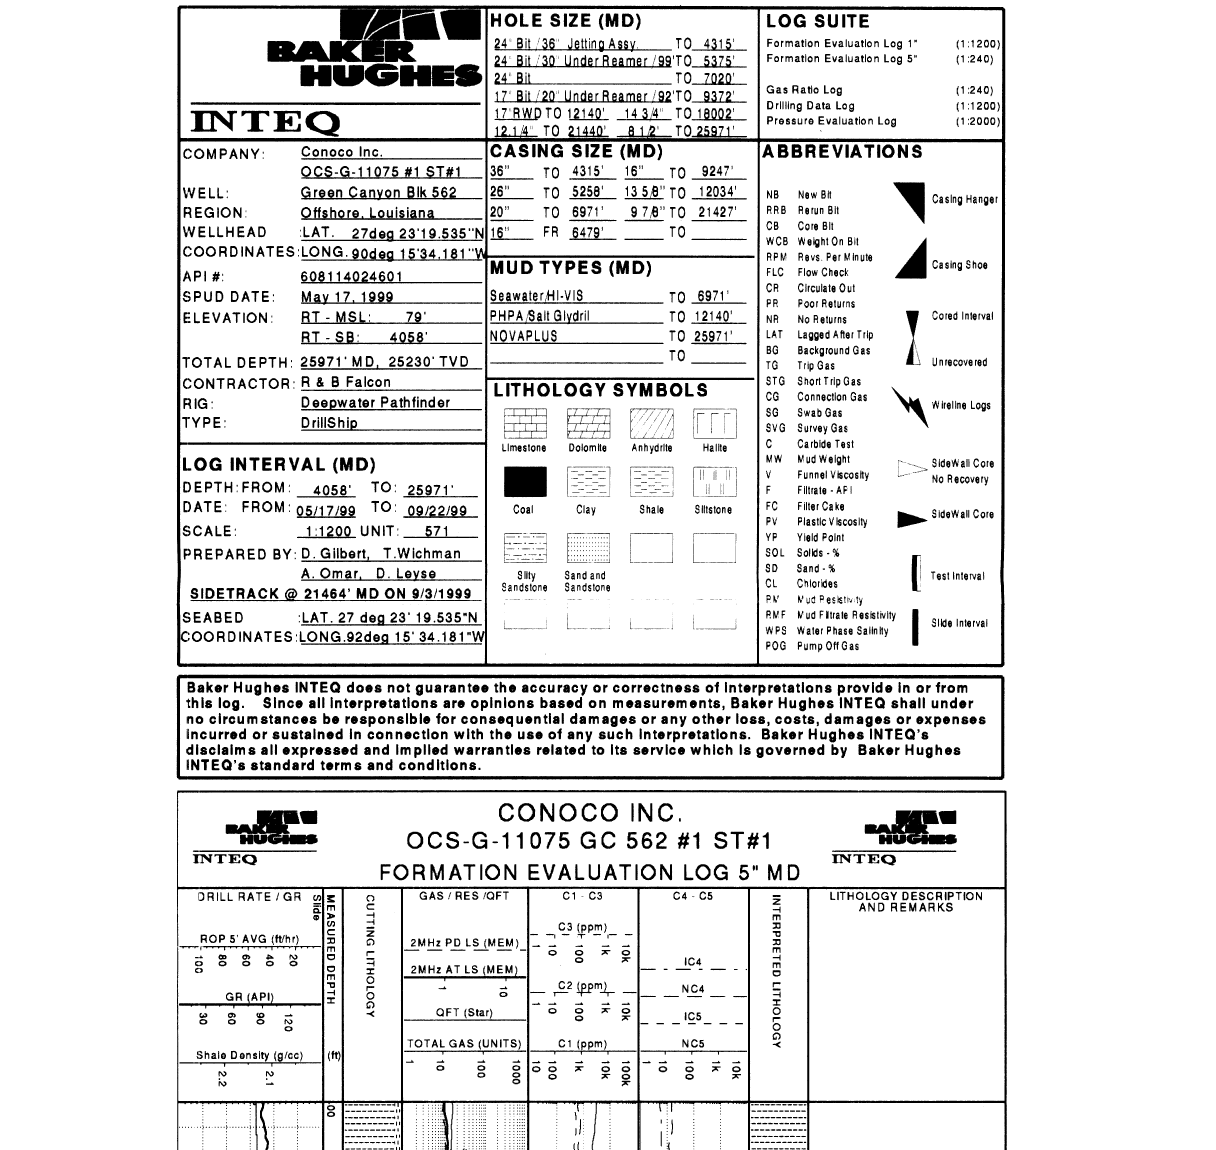

In [2]:
image = Image.open(IMAGE_PATH)
print("size (width x height):", image.size)
print("mode:", image.mode, "(1 = black & white)")


def crop_rgb(img, box, scale=1.0, strip=2000):
    """Crop box=(x0, y0, x1, y1) out of img as RGB, optionally shrunk by `scale`.
    The crop is converted and shrunk `strip` rows at a time, so even a 1-bit image that is
    100,000+ px tall never has to exist at full size as RGB."""
    x0, y0, x1, y1 = box
    out = Image.new("RGB", (round((x1 - x0) * scale), round((y1 - y0) * scale)))
    for ys in range(y0, y1, strip):
        ye = min(ys + strip, y1)
        part = img.crop((x0, ys, x1, ye)).convert("RGB")
        top, bottom = round((ys - y0) * scale), round((ye - y0) * scale)
        if scale != 1.0:
            part = part.resize((out.width, max(1, bottom - top)), Image.Resampling.BOX)
        out.paste(part, (0, top))
    return out


# the top of the page: the header block followed by the log's title and column headings
crop_rgb(image, (0, 0, image.width, 4600), scale=0.25)

## 3. Load the annotation and plot the bounding boxes

The annotation is a small JSON file. Boxes are `[x_min, y_min, x_max, y_max]` in **pixels, origin at the top-left**,
and `x_max` / `y_max` are *exclusive* (so `image.crop(box)` returns exactly the boxed region).

In [3]:
annotation = json.loads(ANNOTATION_PATH.read_text())
boxes = annotation["bounding_boxes"]

assert (annotation["width"], annotation["height"]) == image.size  # the annotation belongs to this image
print(annotation["coordinate_system"])
for name, (x0, y0, x1, y1) in boxes.items():
    print(f"{name:30s} x {x0:5d}-{x1:5d}   y {y0:6d}-{y1:6d}   ({x1 - x0} x {y1 - y0} px)")

pixels, origin at top-left, x_max and y_max exclusive
depth_column                   x  1288- 1376   y   4404- 11195   (88 x 6791 px)
interpreted_lithology_column   x  2991- 3237   y   4404- 11195   (246 x 6791 px)
lithology_legend               x  1943- 3035   y   1513-  2655   (1092 x 1142 px)


`draw_boxes` draws every box on a crop. Because we usually plot a *crop* of the image rather than the whole thing,
it takes the crop's `origin` and `scale` and converts the box coordinates for us.

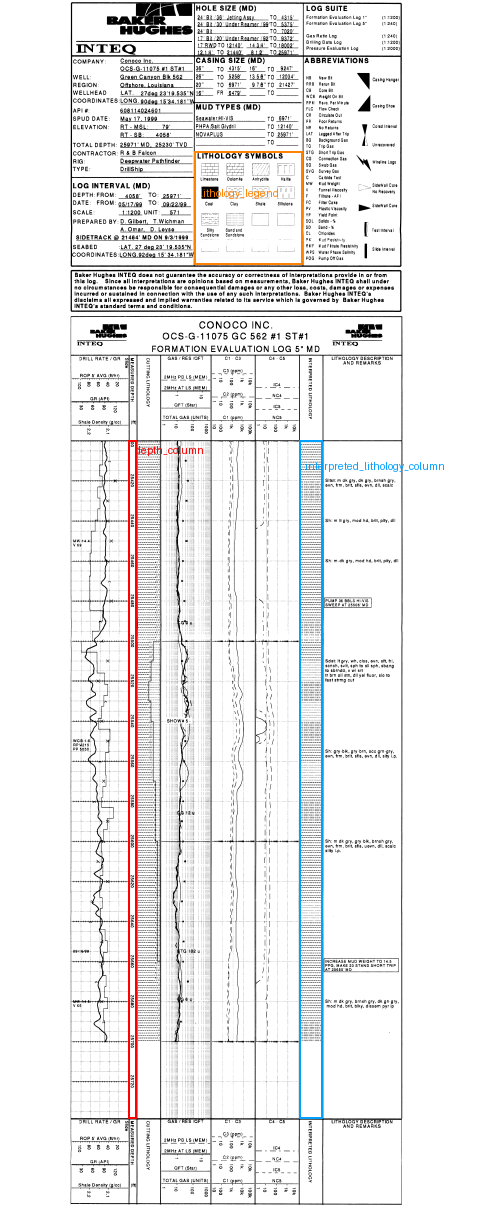

In [4]:
BOX_COLORS = {
    "depth_column": (255, 0, 0),
    "interpreted_lithology_column": (0, 160, 255),
    "lithology_legend": (255, 130, 0),
}


def draw_boxes(img, boxes, origin=(0, 0), scale=1.0, line_width=4, font_size=16):
    """Draw boxes (given in full-image pixels) on img, a crop that starts at `origin` and was scaled by `scale`."""
    draw = ImageDraw.Draw(img)
    font = get_font(font_size)
    for i, (name, (x0, y0, x1, y1)) in enumerate(boxes.items()):
        color = BOX_COLORS.get(name, (0, 200, 0))
        rect = [(x0 - origin[0]) * scale, (y0 - origin[1]) * scale, (x1 - origin[0]) * scale - 1, (y1 - origin[1]) * scale - 1]
        if rect[3] < 0 or rect[1] > img.height or rect[2] < 0 or rect[0] > img.width:
            continue  # this box lies outside the crop
        draw.rectangle(rect, outline=color, width=line_width)
        draw.text((rect[0] + 6, max(rect[1], 0) + 4 + (font_size + 4) * i), name, fill=color, font=font)
    return img


# (a) the whole page, shrunk: the two columns run the full length of the log, the legend sits in the header
scale = 0.1
overview = crop_rgb(image, (0, 0, image.width, image.height), scale)
draw_boxes(overview, boxes, scale=scale, line_width=2, font_size=12)

## 4. Load the example output (`example.csv`)

One row per lithology interval:

| column | meaning |
|---|---|
| `top_depth`, `bottom_depth` | depth range of the interval |
| `lithology` | predicted lithology |
| `cluster_id` | *(optional)* the cluster the interval belongs to; drawn next to the interval when present |
| `top_y`, `bottom_y` | where the interval sits in the image, in the **same pixel coordinates as the bounding boxes** |

In [5]:
def load_results(path):
    """Read a results CSV (top_depth, bottom_depth, lithology, top_y, bottom_y, and optionally cluster_id) into a list of dicts."""
    with open(path, newline="") as f:
        return [
            {"top_depth": float(r["top_depth"]), "bottom_depth": float(r["bottom_depth"]), "lithology": r["lithology"],
             "top_y": int(r["top_y"]), "bottom_y": int(r["bottom_y"]),
             "cluster_id": r.get("cluster_id") or None}  # cluster_id is optional
            for r in csv.DictReader(f)
        ]


results = load_results(RESULTS_PATH)

print(f"{'depth':>15s}  {'lithology':10s}  {'rows (px)':>13s}  cluster_id")
for r in results:
    print(f"{r['top_depth']:7.0f}-{r['bottom_depth']:<7.0f}  {r['lithology']:10s}  {r['top_y']:6d}-{r['bottom_y']:<6d}  {r['cluster_id']}")

# sanity check: the intervals follow each other without gaps and stay inside the interpreted-lithology column
lith_box = boxes["interpreted_lithology_column"]
assert all(a["bottom_y"] == b["top_y"] for a, b in zip(results, results[1:]))
assert lith_box[1] <= results[0]["top_y"] and results[-1]["bottom_y"] <= lith_box[3]

          depth  lithology       rows (px)  cluster_id
  25400-25420    Shale         4409-4809    0
  25420-25430    Siltstone     4809-5010    1
  25430-25490    Shale         5010-6211    0
  25490-25500    Siltstone     6211-6411    1
  25500-25510    Shale         6411-6611    0
  25510-25520    Sandstone     6611-6811    2
  25520-25530    Siltstone     6811-7012    1
  25530-25540    Sandstone     7012-7212    2
  25540-25550    Siltstone     7212-7412    1
  25550-25560    Shale         7412-7612    0
  25560-25570    Sandstone     7612-7812    2
  25570-25580    Shale         7812-8013    0
  25580-25590    Siltstone     8013-8213    1
  25590-25630    Shale         8213-9014    0
  25630-25640    Sandstone     9014-9214    2
  25640-25690    Shale         9214-10215   0
  25690-25700    Siltstone    10215-10415   1


## 5. Visualise the results
`visualize_results` does the whole visualisation in one call, so for new data you only need three inputs: the **image**, the **bounding boxes**
and the **results CSV**. Each can be a path or an already-loaded object (a `PIL.Image` and a `dict`).
It returns the finished picture (colour key on top) and can also save it.

| argument | meaning |
|---|---|
| `image` | path to the log image, or a `PIL.Image` |
| `bboxes` | path to the annotation JSON, or its dict (it needs `depth_column` and `interpreted_lithology_column`) |
| `results` | path to the results CSV, or the list returned by `load_results` |
| `save_path` | optional: where to write a PNG |
| `scale` | shrink factor for the whole picture (default 0.25; `1.0` = original size). Use a smaller value for very tall logs |
| `coverage` | fraction of the lithology column that is painted (default 0.5) |
| `colors` | optional `{label: (r, g, b)}`; by default colours are assigned automatically from the labels in the CSV |

drew 17 intervals and 18 boundary labels


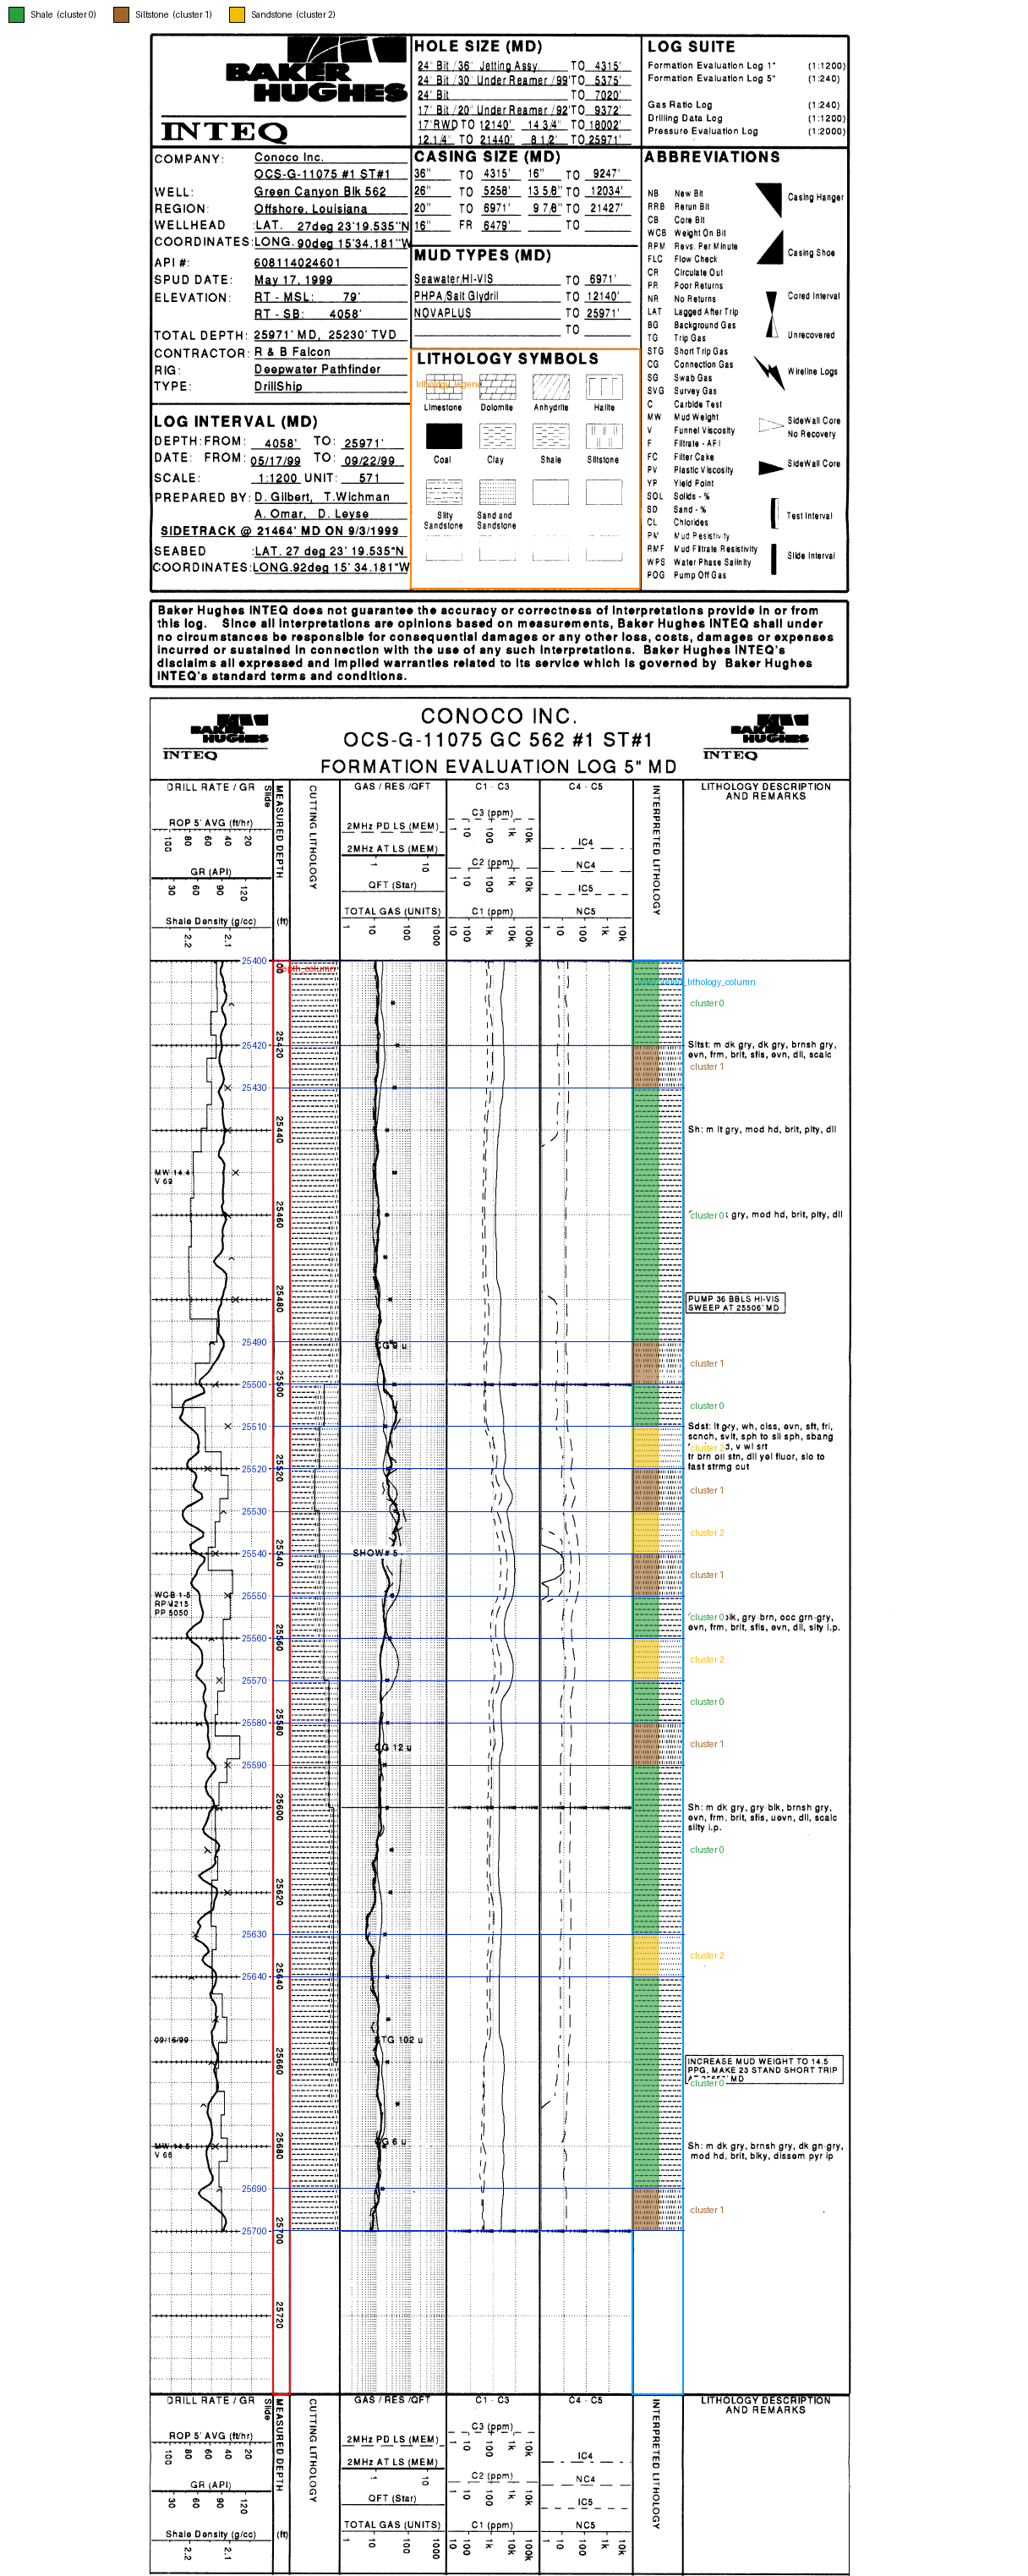

In [6]:
PALETTE = [(40, 160, 60), (160, 100, 40), (240, 190, 0), (150, 60, 170), (0, 150, 150), (230, 110, 20),
           (200, 60, 120), (110, 110, 110)]
LINE_COLOR = (0, 40, 200)  

def build_color_map(labels):
    """Give every distinct label its own colour, in order of first appearance. Works for any labels:
    the palette is used first, then extra hues are generated, so nothing is hard-coded per lithology."""
    colors = {}
    for label in labels:
        if label in colors:
            continue
        i = len(colors)
        if i < len(PALETTE):
            colors[label] = PALETTE[i]
        else:  # beyond the palette: spread hues with the golden ratio so neighbours stay distinct
            h = (i * 0.618034) % 1.0
            colors[label] = tuple(int(255 * c) for c in colorsys.hsv_to_rgb(h, 0.65, 0.8))
    return colors


def overlay_results(img, results, colors, column_box, depth_box, origin, scale, alpha=150, coverage=0.5):
    """Paint every interval over the left `coverage` of the lithology column on `img` (a crop starting at
    `origin`, shrunk by `scale`) in the colour given for its label in `colors`, so the original column stays visible on the right. At every interval
    boundary a thin line runs from the depth column to the lithology column and the boundary depth is written
    to the left of the depth column, and the interval's cluster id (if it has one) to the right of the lithology
    column. Every row of `results` is drawn, however small the interval."""
    overlay = Image.new("RGBA", img.size, (0, 0, 0, 0))
    draw = ImageDraw.Draw(overlay)
    font = get_font(13)
    x0, x1 = (column_box[0] - origin[0]) * scale, (column_box[2] - origin[0]) * scale
    xm = x0 + (x1 - x0) * coverage  # right edge of the painted part
    xd = (depth_box[0] - origin[0]) * scale  # left edge of the depth column
    boundaries = {}  # y (full-image pixels) -> depths given at that boundary
    for r in results:
        y0, y1 = (r["top_y"] - origin[1]) * scale, (r["bottom_y"] - origin[1]) * scale
        color = colors[r["lithology"]]
        draw.rectangle([x0, y0, xm, y1], fill=color + (alpha,), outline=color + (255,), width=1)
        if r.get("cluster_id") is not None:
            draw.text((x1 + 8, (y0 + y1) / 2), f"cluster {r['cluster_id']}", fill=color + (255,), font=font, anchor="lm",
                      stroke_width=3, stroke_fill=(255, 255, 255, 255))
        boundaries.setdefault(r["top_y"], []).append(r["top_depth"])
        boundaries.setdefault(r["bottom_y"], []).append(r["bottom_depth"])
    for y, depths in boundaries.items():
        yy = (y - origin[1]) * scale
        draw.line([(xd, yy), (x1, yy)], fill=LINE_COLOR + (255,), width=1)
        label = " / ".join(f"{d:g}" for d in dict.fromkeys(depths))  # more than one value only if the depths jump
        draw.text((xd - 6, yy), label, fill=LINE_COLOR + (255,), font=font, anchor="rm",
                  stroke_width=3, stroke_fill=(255, 255, 255, 255))
    print(f"drew {len(results)} intervals and {len(boundaries)} boundary labels")
    return Image.alpha_composite(img.convert("RGBA"), overlay).convert("RGB")


def add_legend(img, colors, clusters=None, row_height=34):
    """Return img with a white bar on top holding one colour swatch per label (wrapping onto more rows if needed).
    `clusters` ({label: [cluster ids]}) adds the cluster ids found for each label next to its name."""
    clusters = clusters or {}
    font = get_font(15)
    measure = ImageDraw.Draw(Image.new("RGB", (1, 1)))
    slots, x, row = [], 10, 0
    texts = {name: name + (f"  (cluster {', '.join(clusters[name])})" if clusters.get(name) else "") for name in colors}
    for name in colors:
        w = 26 + int(measure.textlength(texts[name], font=font)) + 20
        if x + w > img.width and x > 10:  # no room left on this row: start a new one
            x, row = 10, row + 1
        slots.append((name, x, row))
        x += w
    bar = row_height * (row + 1)
    out = Image.new("RGB", (img.width, img.height + bar), (255, 255, 255))
    out.paste(img, (0, bar))
    draw = ImageDraw.Draw(out)
    for name, x, row in slots:
        y = row * row_height
        draw.rectangle([x, y + 8, x + 18, y + 26], fill=colors[name], outline=(0, 0, 0))
        draw.text((x + 26, y + 17), texts[name], fill=(0, 0, 0), font=font, anchor="lm")
    return out


def visualize_results(image, bboxes, results, scale=0.25, save_path=None, coverage=0.5, colors=None):
    """Plot the results CSV on the whole log image: coloured intervals over the lithology column, boundary lines and
    depths next to the depth column, cluster ids next to the lithology column, and a colour key on top.
    Nothing is cropped. `scale` shrinks the picture (1.0 = original size). Returns a PIL image."""
    if not isinstance(image, Image.Image):
        image = Image.open(image)
    if not isinstance(bboxes, dict):
        bboxes = json.loads(Path(bboxes).read_text())
    if not isinstance(results, list):
        results = load_results(results)
    boxes = bboxes.get("bounding_boxes", bboxes)  # accept the whole annotation file or just its boxes
    if colors is None:
        colors = build_color_map(r["lithology"] for r in results)

        view = crop_rgb(image, (0, 0, image.width, image.height), scale)
    view = draw_boxes(view, boxes, scale=scale, line_width=2, font_size=12)
    view = overlay_results(view, results, colors, boxes["interpreted_lithology_column"], boxes["depth_column"],
                           (0, 0), scale, coverage=coverage)
    clusters = {}  # label -> cluster ids seen for it, in order of first appearance
    for r in results:
        if r.get("cluster_id") is not None:
            clusters.setdefault(r["lithology"], [])
            if r["cluster_id"] not in clusters[r["lithology"]]:
                clusters[r["lithology"]].append(r["cluster_id"])
    view = add_legend(view, colors, clusters)
    if save_path is not None:
        view.save(save_path)
    return view


visualize_results(IMAGE_PATH, ANNOTATION_PATH, RESULTS_PATH)
